In [1]:
import unophysics as uno

fn = "../sample_data/71621DC7.190"

e = uno.ladc.EARS(fn)

WARNING --- unophysics.cred file not found


In [2]:
e

EARS object attributes: ['__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', '__weakref__', 'data', 'default_fn', 'epoch', 'epochs', 'filename', 'fs', 'fs_time', 'header2timestamp', 'headerN', 'headers', 'load', 'norm', 'recN', 'time_0', 'time_f', 'timestamps', 'year']
Sampling frequency (fs): 192000
Data length: 4096000
First 10 samples: [174, 178, 181, 178, 180, 181, 181, 175, 177, 177]


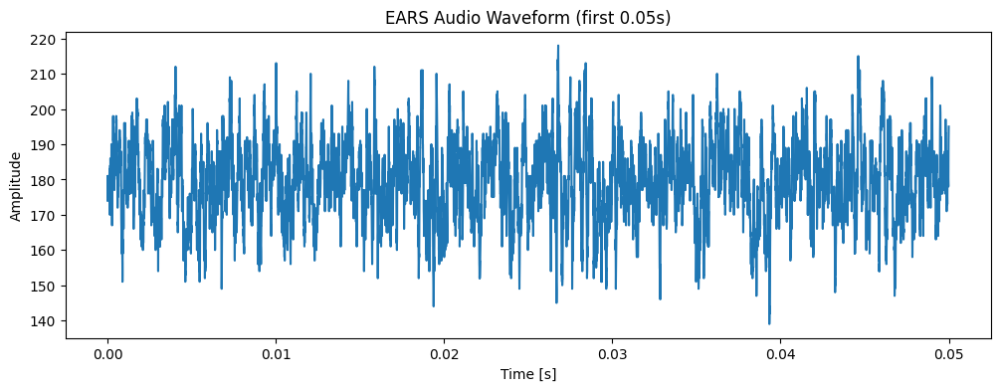

In [5]:
# Explore EARS object fields and audio data
print('EARS object attributes:', dir(e))
print('Sampling frequency (fs):', getattr(e, 'fs', 'Not found'))
if hasattr(e, 'data'):
    data = getattr(e, 'data')
    if hasattr(data, 'shape'):
        print('Data shape:', data.shape)
    else:
        print('Data length:', len(data))
    print('First 10 samples:', data[:10])
else:
    print('No data attribute')

# Plot a short segment of the waveform if data exists
import matplotlib.pyplot as plt
import numpy as np

if hasattr(e, 'data') and hasattr(e, 'fs') and isinstance(e.data, (np.ndarray, list)) and len(e.data) > 0:
    plt.figure(figsize=(12, 4))
    t = np.arange(len(e.data)) / e.fs
    plt.plot(t[:int(e.fs*0.05)], np.array(e.data)[:int(e.fs*0.05)])  # Plot first 0.05 seconds
    plt.title('EARS Audio Waveform (first 0.05s)')
    plt.xlabel('Time [s]')
    plt.ylabel('Amplitude')
    plt.show()
else:
    print('No valid data or fs attribute to plot.')

# Try to play audio (if in notebook and data is in range)
try:
    from IPython.display import Audio
    # Normalize data to -1..1 for playback if needed
    data = np.array(e.data)
    if data.dtype != np.float32 and data.dtype != np.float64:
        data = data.astype(np.float32)
    maxabs = np.max(np.abs(data))
    if maxabs > 0:
        data = data / maxabs
    display(Audio(data, rate=int(e.fs)))
except Exception as ex:
    print('Audio playback not available:', ex)